# Ajuste de Hiperparámetros

Caso de estudio: Ecommerce Customer Dataset  
Asignatura: MLY1101 Machine Learning  
Actividad 3.1.2, Guía de Ajuste de Hiperparámetros en Scikit-Learn

## Descripción

Los hiperparámetros por defecto de scikit-learn dejan a los modelos lejos de su mejor rendimiento.
En este notebook ajustamos los dos modelos que pide la guía, cada uno con una estrategia distinta.
En el Paso 1 usamos GridSearchCV en un árbol de decisión que predice el abandono (Exited), probando
todas las combinaciones de una grilla. En el Paso 2 usamos RandomizedSearchCV en una regresión Ridge
que estima el saldo (Balance), con un presupuesto de 20 combinaciones al azar.

En ambos casos los hiperparámetros se eligen con validación cruzada de 5 pliegues sobre el
entrenamiento. En el Paso 1, el conjunto de prueba se usa una sola vez, al final, para comparar el
árbol ajustado con el árbol por defecto.

## Requisitos de Software

Las versiones exactas están en [`requirements.txt`](../requirements.txt): pandas 2.3.3, numpy 2.0.2,
matplotlib 3.9.4, scipy 1.15.3 y scikit-learn 1.6.1.

# Importación de librerías

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('bmh')

from scipy.stats import loguniform
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score
from sklearn.model_selection import (GridSearchCV, KFold, RandomizedSearchCV, StratifiedKFold,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Advertencia espuria de numpy con la librería de cálculo de macOS; no afecta los resultados.
warnings.filterwarnings('ignore', message='.*encountered in matmul', category=RuntimeWarning)
os.environ['PYTHONWARNINGS'] = ','.join(
    f'ignore:{problema} encountered in matmul:RuntimeWarning'
    for problema in ['divide by zero', 'overflow', 'invalid value']
)

os.makedirs('../images', exist_ok=True)
SEMILLA = 42

# Reconstrucción de la preparación de datos

Repetimos sin cambios la carga, las variables derivadas, la partición 80/20 estratificada por Exited
y el pipeline de preparación de [`preprocesamiento.ipynb`](preprocesamiento.ipynb) y
[`modelamiento.ipynb`](modelamiento.ipynb). Así el notebook corre por sí solo y trabaja con los
mismos clientes de entrenamiento y prueba que el resto del proyecto.

In [2]:
df = pd.read_csv('../data/ecommerce_customer_data.csv')
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

df['tiene_saldo'] = (df['Balance'] > 0).astype(int)

features_num = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary', 'distancia_edad_riesgo']
features_cat = ['Geography', 'Gender', 'NumOfProducts']
features_bin = ['HasCrCard', 'IsActiveMember', 'tiene_saldo']

features_num_reg = [col for col in features_num if col != 'Balance']
features_bin_reg = [col for col in features_bin if col != 'tiene_saldo']

# distancia_edad_riesgo todavía no existe: se agrega después de la partición
features_base = [col for col in features_num + features_cat + features_bin if col != 'distancia_edad_riesgo']
X = df[features_base]
y_clf = df['Exited']
y_reg = df['Balance']

X_train, X_test, y_clf_train, y_clf_test, y_reg_train, y_reg_test = train_test_split(
    X, y_clf, y_reg, test_size=0.2, stratify=y_clf, random_state=SEMILLA
)

# El centro de la U invertida se aprende de Exited, así que se elige solo con el entrenamiento
correlacion_por_centro = {c: (X_train['Age'] - c).abs().corr(y_clf_train) for c in range(40, 66)}
CENTRO_EDAD = max(correlacion_por_centro, key=lambda c: abs(correlacion_por_centro[c]))
X_train = X_train.assign(distancia_edad_riesgo=(X_train['Age'] - CENTRO_EDAD).abs())
X_test = X_test.assign(distancia_edad_riesgo=(X_test['Age'] - CENTRO_EDAD).abs())

print(f'Entrenamiento: {X_train.shape} | Prueba: {X_test.shape} | Centro de edad: {CENTRO_EDAD} años')

Entrenamiento: (8000, 12) | Prueba: (2000, 12) | Centro de edad: 55 años


In [3]:
class CorrelationFilter(BaseEstimator, TransformerMixin):
    """
    Elimina variables con alta correlación (multicolinealidad). Las columnas a eliminar se
    aprenden en fit (conjunto de entrenamiento) y se aplican igual en transform.
    """
    def __init__(self, threshold=0.9):
        self.threshold = threshold

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        corr_matrix = X_df.corr().abs()
        upper = corr_matrix.where(
            np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
        )
        self.columns_to_drop_ = [
            col for col in upper.columns if any(upper[col] > self.threshold)
        ]
        return self

    def transform(self, X):
        return pd.DataFrame(X).drop(columns=self.columns_to_drop_, errors='ignore')


def construir_pipeline_preparacion(num_cols, cat_cols, bin_cols):
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler())
    ])

    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot',  OneHotEncoder(drop='first', handle_unknown='error', sparse_output=False))
    ])

    preprocesador = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer,     num_cols),
            ('cat', categorical_transformer, cat_cols),
            ('bin', 'passthrough',           bin_cols)
        ],
        remainder='drop'
    ).set_output(transform='pandas')

    return Pipeline(steps=[
        ('preprocesador', preprocesador),
        ('colinealidad',  CorrelationFilter(threshold=0.9))
    ])


def modelo_completo(num_cols, cat_cols, bin_cols, estimador):
    """
    Pipeline de preparación + modelo: se entrena todo junto solo con el conjunto de entrenamiento.
    Usa una copia sin entrenar del estimador (clone), para que dos pipelines nunca compartan
    el mismo modelo entrenado.
    """
    return Pipeline(steps=[
        ('preparacion', construir_pipeline_preparacion(num_cols, cat_cols, bin_cols)),
        ('modelo',      clone(estimador))
    ])

# Paso 1: Optimización exhaustiva de clasificación (GridSearchCV)

Modelo: árbol de decisión. Variable objetivo: Exited (1 = abandonó).

## 1.1 Punto de partida: el árbol por defecto

Sin restricciones, el árbol crece hasta que cada hoja tiene clientes de una sola clase. Antes de
ajustar nada medimos cómo le va, tanto en validación cruzada (con los mismos 5 pliegues que usará la
búsqueda) como en el conjunto de prueba.

In [4]:
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
metricas_clf = {'F1': 'f1', 'Recall': 'recall', 'Precisión': 'precision'}

arbol_defecto = modelo_completo(features_num, features_cat, features_bin,
                                DecisionTreeClassifier(random_state=SEMILLA))

cv_arbol_defecto = cross_validate(arbol_defecto, X_train, y_clf_train, cv=cv_clf, scoring=metricas_clf,
                                  return_train_score=True)
print(f"F1 en validación cruzada: {cv_arbol_defecto['test_F1'].mean():.3f} ± "
      f"{cv_arbol_defecto['test_F1'].std():.3f} (entrenamiento: {cv_arbol_defecto['train_F1'].mean():.3f})")

arbol_defecto.fit(X_train, y_clf_train)

print(f"Profundidad: {arbol_defecto['modelo'].get_depth()} | "
      f"Hojas: {arbol_defecto['modelo'].get_n_leaves()}")
print(f"F1 en entrenamiento: {f1_score(y_clf_train, arbol_defecto.predict(X_train)):.3f}\n")
print('Árbol por defecto, en prueba:')
print(classification_report(y_clf_test, arbol_defecto.predict(X_test),
                            target_names=['Se mantiene (0)', 'Abandona (1)'], digits=3))

F1 en validación cruzada: 0.486 ± 0.021 (entrenamiento: 1.000)
Profundidad: 25 | Hojas: 1149
F1 en entrenamiento: 1.000

Árbol por defecto, en prueba:
                 precision    recall  f1-score   support

Se mantiene (0)      0.872     0.848     0.860      1593
   Abandona (1)      0.462     0.511     0.485       407

       accuracy                          0.779      2000
      macro avg      0.667     0.680     0.673      2000
   weighted avg      0.788     0.779     0.784      2000



El árbol por defecto memoriza el entrenamiento. Llega a 25 niveles y 1.149 hojas, con F1 de 1,000 en
entrenamiento, pero en prueba baja a 0,485: detecta 208 de los 407 abandonos y genera 242 falsas
alarmas. La validación cruzada da prácticamente lo mismo (0,486 ± 0,021), así que no es un problema
de esta partición. Es un caso claro de sobreajuste, y ese 0,486 es la referencia contra la que
comparamos la búsqueda.

## 1.2 Búsqueda por malla con validación cruzada de 5 pliegues

La grilla combina cuatro hiperparámetros. max_depth limita cuántas preguntas encadenadas puede hacer
el árbol, min_samples_split fija cuántos clientes necesita un nodo para dividirse y min_samples_leaf
cuántos deben quedar en cada hoja. Los tres sirven para frenar el sobreajuste. El cuarto,
class_weight, prueba darles más peso a los abandonos ('balanced'), que son solo el 20,4% de los
clientes y justamente los falsos negativos que preocupan a la guía.

Gana la combinación con mejor F1 promedio, la métrica que pide la guía, porque equilibra precisión y
recall. Los pliegues son estratificados y la búsqueda recorre el pipeline completo, de modo que el
escalado y el one hot se recalculan en cada pliegue sin ver la parte de validación.

In [5]:
grilla_arbol = {
    'modelo__max_depth':         [3, 4, 5, 6, 8, 10, 12, None],
    'modelo__min_samples_split': [2, 20, 50, 100, 200],
    'modelo__min_samples_leaf':  [1, 10, 30, 60],
    'modelo__class_weight':      [None, 'balanced'],
}
n_combinaciones = int(np.prod([len(valores) for valores in grilla_arbol.values()]))
print(f'Combinaciones: {n_combinaciones} | Entrenamientos: {n_combinaciones} × 5 pliegues = '
      f'{n_combinaciones * 5} (+1 reentrenamiento final con todo el entrenamiento)')

grid_search = GridSearchCV(
    modelo_completo(features_num, features_cat, features_bin, DecisionTreeClassifier(random_state=SEMILLA)),
    param_grid=grilla_arbol,
    scoring=metricas_clf,
    refit='F1', cv=cv_clf, n_jobs=-1, return_train_score=True,
)
grid_search.fit(X_train, y_clf_train)

print(f'\nMejor combinación: {grid_search.best_params_}')
print(f'F1 en validación cruzada: {grid_search.best_score_:.3f}')

Combinaciones: 320 | Entrenamientos: 320 × 5 pliegues = 1600 (+1 reentrenamiento final con todo el entrenamiento)



Mejor combinación: {'modelo__class_weight': None, 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 1, 'modelo__min_samples_split': 200}
F1 en validación cruzada: 0.578


La mejor combinación es max_depth = 10, min_samples_split = 200, min_samples_leaf = 1 y class_weight
= None, con F1 de 0,578 ± 0,020 en validación cruzada (320 combinaciones y 1.600 entrenamientos).
Con los mismos pliegues, son 0,092 puntos más que el árbol por defecto.

## 1.3 Evaluación en el conjunto de prueba

In [6]:
mejor_arbol = grid_search.best_estimator_   # ya reentrenado con todo el entrenamiento
print(f"Profundidad: {mejor_arbol['modelo'].get_depth()} | Hojas: {mejor_arbol['modelo'].get_n_leaves()}\n")
print('Árbol ajustado, en prueba:')
print(classification_report(y_clf_test, grid_search.best_estimator_.predict(X_test),
                            target_names=['Se mantiene (0)', 'Abandona (1)'], digits=3))

Profundidad: 10 | Hojas: 65

Árbol ajustado, en prueba:
                 precision    recall  f1-score   support

Se mantiene (0)      0.894     0.933     0.913      1593
   Abandona (1)      0.683     0.568     0.620       407

       accuracy                          0.859      2000
      macro avg      0.789     0.750     0.767      2000
   weighted avg      0.851     0.859     0.853      2000



In [7]:
def resumen_clasificacion(modelo):
    pred_train, pred_test = modelo.predict(X_train), modelo.predict(X_test)
    return {
        'F1 entrenamiento': f1_score(y_clf_train, pred_train),
        'F1 prueba':        f1_score(y_clf_test, pred_test),
        'Recall prueba':    recall_score(y_clf_test, pred_test),
        'Precisión prueba': precision_score(y_clf_test, pred_test),
        'Abandonos detectados': int(((pred_test == 1) & (y_clf_test == 1)).sum()),
        'Abandonos no detectados': int(((pred_test == 0) & (y_clf_test == 1)).sum()),
        'Falsas alarmas':   int(((pred_test == 1) & (y_clf_test == 0)).sum()),
    }

comparacion_arbol = pd.DataFrame({'Árbol por defecto': resumen_clasificacion(arbol_defecto),
                                  'Árbol ajustado':    resumen_clasificacion(mejor_arbol)}).T
columnas_conteo = ['Abandonos detectados', 'Abandonos no detectados', 'Falsas alarmas']
comparacion_arbol[columnas_conteo] = comparacion_arbol[columnas_conteo].astype(int)
comparacion_arbol.round(3)

,F1 entrenamiento,F1 prueba,Recall prueba,Precisión prueba,Abandonos detectados,Abandonos no detectados,Falsas alarmas
Árbol por defecto,1.000,0.485,0.511,0.462,208,199,242
Árbol ajustado,0.625,0.620,0.568,0.683,231,176,107


### ¿Superó el F1 al modelo por defecto?

Sí. En prueba el F1 sube de 0,485 a 0,620. La precisión pasa de 0,462 a 0,683, con lo que las falsas
alarmas bajan de 242 a 107, y el recall de 0,511 a 0,568, lo que equivale a 23 abandonos más
detectados.

También desaparece el sobreajuste. El F1 en entrenamiento (0,625) y en prueba (0,620) son casi
iguales, y el árbol pasa de 1.149 a 65 hojas, lo que además lo hace mucho más fácil de leer. El
resultado en prueba es coherente con la validación cruzada (0,578 ± 0,020), así que la mejora no
depende de cómo quedó armado el conjunto de prueba.

## 1.4 Impacto de max_depth

Para aislar el efecto de la profundidad, fijamos los demás hiperparámetros (primero en sus mejores
valores y luego sin restricciones de tamaño) y comparamos el F1 de entrenamiento con el de
validación para cada valor de max_depth.

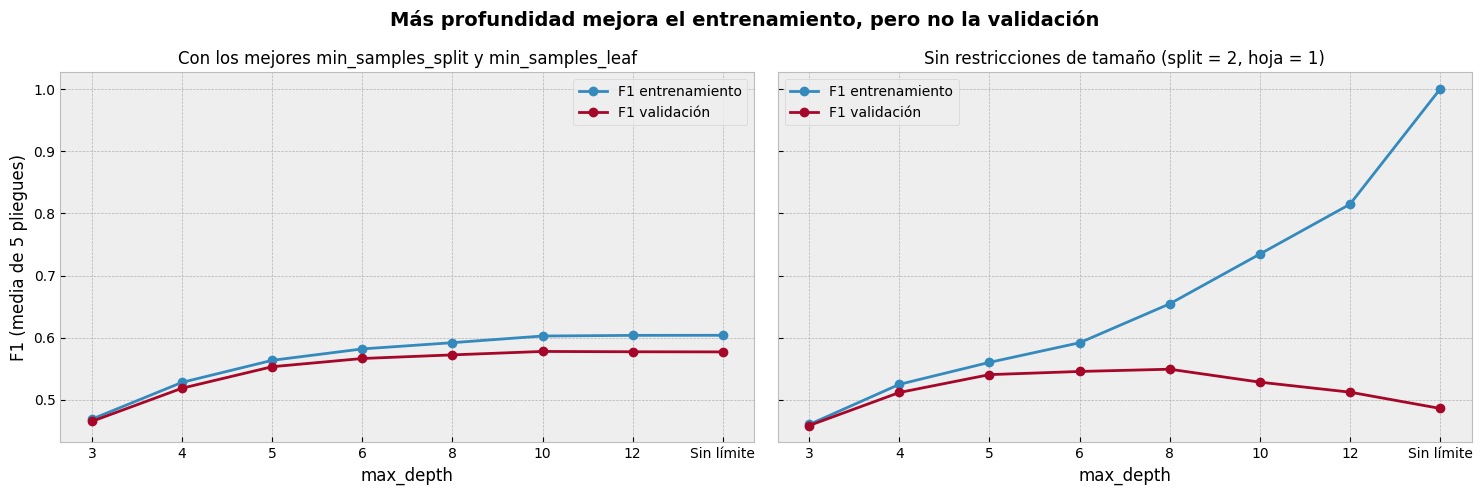

Con los mejores split y hoja                       \
                       F1 entrenamiento F1 validación Brecha   
max_depth                                                      
3                                 0.469         0.465  0.004   
4                                 0.528         0.519  0.009   
5                                 0.564         0.553  0.010   
6                                 0.582         0.567  0.015   
8                                 0.592         0.572  0.020   
10                                0.603         0.578  0.025   
12                                0.604         0.577  0.026   
Sin límite                        0.604         0.577  0.027   

           Sin restricciones de tamaño                       
                      F1 entrenamiento F1 validación Brecha  
max_depth                                                    
3                                0.460         0.459  0.002  
4                                0.525         0.512  0.013  
5                                0.560         0.541  0.020  
6                                0.592         0.546  0.046  
8                                0.654         0.549  0.105  
10                               0.735         0.528  0.206  
12                               0.815         0.512  0.302  
Sin límite                       1.000         0.486  0.514

In [8]:
resultados_arbol = pd.DataFrame(grid_search.cv_results_)
mejores = grid_search.best_params_
mascara = np.ones(len(resultados_arbol), dtype=bool)
for parametro in ['modelo__min_samples_split', 'modelo__min_samples_leaf', 'modelo__class_weight']:
    mascara &= resultados_arbol[f'param_{parametro}'].astype(str) == str(mejores[parametro])

por_profundidad = (resultados_arbol[mascara]
                   .assign(max_depth=lambda d: d['param_modelo__max_depth'].astype(str).replace('None', 'Sin límite'))
                   .set_index('max_depth')[['mean_train_F1', 'mean_test_F1']]
                   .rename(columns={'mean_train_F1': 'F1 entrenamiento', 'mean_test_F1': 'F1 validación'}))
por_profundidad['Brecha'] = por_profundidad['F1 entrenamiento'] - por_profundidad['F1 validación']

# Mismo análisis para el árbol sin restricciones de tamaño (min_samples_split=2, min_samples_leaf=1)
mascara_libre = ((resultados_arbol['param_modelo__min_samples_split'] == 2)
                 & (resultados_arbol['param_modelo__min_samples_leaf'] == 1)
                 & (resultados_arbol['param_modelo__class_weight'].astype(str) == str(mejores['modelo__class_weight'])))
libre = (resultados_arbol[mascara_libre]
         .assign(max_depth=lambda d: d['param_modelo__max_depth'].astype(str).replace('None', 'Sin límite'))
         .set_index('max_depth')[['mean_train_F1', 'mean_test_F1']])

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (datos, titulo) in zip(axes, [(por_profundidad, 'Con los mejores min_samples_split y min_samples_leaf'),
                                      (libre.rename(columns={'mean_train_F1': 'F1 entrenamiento',
                                                             'mean_test_F1': 'F1 validación'}),
                                       'Sin restricciones de tamaño (split = 2, hoja = 1)')]):
    datos[['F1 entrenamiento', 'F1 validación']].plot(ax=ax, marker='o')
    ax.set_title(titulo, fontsize=12)
    ax.set_xlabel('max_depth')
    ax.set_xticks(range(len(datos)))
    ax.set_xticklabels(datos.index)
axes[0].set_ylabel('F1 (media de 5 pliegues)')
plt.suptitle('Más profundidad mejora el entrenamiento, pero no la validación', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../images/tuning_arbol_profundidad.png', dpi=150, bbox_inches='tight')
plt.show()

libre.columns = ['F1 entrenamiento', 'F1 validación']
libre['Brecha'] = libre['F1 entrenamiento'] - libre['F1 validación']
pd.concat({'Con los mejores split y hoja': por_profundidad, 'Sin restricciones de tamaño': libre}, axis=1).round(3)

La profundidad máxima es el principal control entre subajuste y sobreajuste. Con max_depth = 3 el
árbol se queda corto: el F1 es 0,465 en validación y casi igual en entrenamiento, porque no alcanza
a combinar edad, productos y actividad, las variables que según el EDA interactúan. En el otro
extremo, sin otras restricciones (gráfico de la derecha), pasado max_depth = 8 el F1 de
entrenamiento sube hasta 1,000 mientras el de validación cae de 0,549 a 0,486. El árbol empieza a
crear reglas para grupos tan pequeños que no se repiten en clientes nuevos.

Con max_depth = 10 el árbol tiene la profundidad suficiente para captar esas interacciones. La
validación llega a 0,578 y se estabiliza, con una brecha de apenas 0,025 (gráfico de la izquierda).
Eso sí, la profundidad no actúa sola. Como min_samples_split = 200 impide dividir nodos con menos de
200 clientes, el árbol deja de crecer cerca del nivel 10, y por eso max_depth = 12 y sin límite dan
el mismo resultado. Cada regla final se apoya en grupos grandes de clientes, y eso es lo que le
permite generalizar.

# Paso 2: Optimización estocástica y eficiente de regresión (RandomizedSearchCV)

Modelo: regresión Ridge. Variable objetivo: Balance. Usamos las mismas características que en
[`modelamiento.ipynb`](modelamiento.ipynb), es decir, todas menos Balance, tiene_saldo (que se
deriva de él) y Exited.

Ridge es una regresión lineal con regularización L2. Su hiperparámetro principal es alpha, que
controla cuánto se castigan los coeficientes grandes. También probamos cinco solvers (svd, cholesky,
lsqr, sparse_cg y sag), que son los algoritmos que calculan esos coeficientes.

alpha se muestrea de una distribución log uniforme entre 0,001 y 1.000, que le da la misma
probabilidad a cada orden de magnitud. Probamos 20 combinaciones al azar con validación cruzada de 5
pliegues y gana la de menor MAE.

In [9]:
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

distribuciones_ridge = {
    'modelo__alpha':  loguniform(1e-3, 1e3),
    'modelo__solver': ['svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag'],
}

random_search = RandomizedSearchCV(
    modelo_completo(features_num_reg, features_cat, features_bin_reg, Ridge(random_state=SEMILLA)),
    param_distributions=distribuciones_ridge, n_iter=20,
    scoring='neg_mean_absolute_error', cv=cv_reg, random_state=SEMILLA, n_jobs=-1,
)
random_search.fit(X_train, y_reg_train)

print(f"Mejor combinación: alpha {random_search.best_params_['modelo__alpha']:.4f}, "
      f"solver {random_search.best_params_['modelo__solver']}")
print(f"MAE en validación cruzada: {-random_search.best_score_:,.0f}".replace(',', '.'))

Mejor combinación: alpha 0.0014, solver lsqr
MAE en validación cruzada: 44.900


La búsqueda eligió alpha = 0,0014, un valor tan bajo que la regularización casi no actúa y Ridge se
comporta como una regresión lineal común. Tiene sentido, porque la regularización sirve para
corregir el sobreajuste, y aquí cada pliegue entrena con 6.400 clientes para una docena de
variables. El solver no cambia el resultado, ya que los cinco resuelven el mismo problema y solo
difieren en velocidad. El MAE indica que el modelo se equivoca en promedio en unos 44.900 en el
saldo de cada cliente, un error alto si se considera que los saldos distintos de 0 rondan los
120.000.

## 2.1 Desafío: ¿cuántos entrenamientos?

In [10]:
n_iter, n_folds = 20, 5
entrenamientos_random = n_iter * n_folds
entrenamientos_grid = 100 * 5 * n_folds   # 100 valores de alpha × 5 solvers × 5 pliegues

print(f'RandomizedSearchCV: {n_iter} combinaciones × {n_folds} pliegues = {entrenamientos_random} entrenamientos '
      f'(+1 reentrenamiento final)')
print(f'GridSearchCV:       100 alphas × 5 solvers = 500 combinaciones × {n_folds} pliegues = '
      f'{entrenamientos_grid} entrenamientos (+1 reentrenamiento final)')
print(f'GridSearchCV necesitaría {entrenamientos_grid // entrenamientos_random} veces más entrenamientos.')

RandomizedSearchCV: 20 combinaciones × 5 pliegues = 100 entrenamientos (+1 reentrenamiento final)
GridSearchCV:       100 alphas × 5 solvers = 500 combinaciones × 5 pliegues = 2500 entrenamientos (+1 reentrenamiento final)
GridSearchCV necesitaría 25 veces más entrenamientos.


RandomizedSearchCV probó 20 combinaciones en 5 pliegues, es decir, 20 × 5 = 100 entrenamientos, más
uno final con la mejor combinación. Con GridSearchCV, una grilla de 100 valores de alpha y 5 solvers
tendría 500 combinaciones, que en 5 pliegues suman 2.500 entrenamientos, 25 veces más.

La ventaja operativa es que el costo lo fija n_iter y no el tamaño del espacio. En una grilla cada
hiperparámetro nuevo multiplica el costo, como pasa aquí con los 5 solvers, mientras que
RandomizedSearchCV cuesta lo mismo aunque se agreguen hiperparámetros o se amplíen los rangos.
Además, al muestrear alpha de una distribución puede probar cualquier valor del rango y no solo los
de una lista fija.

A cambio, no garantiza encontrar el óptimo exacto, solo uno cercano. Por eso GridSearchCV sigue
siendo preferible cuando el espacio es chico, como en el Paso 1.